# MAttr optimization — official edge baseline

Separate **edge-level** research, using pinned upstream MAttr and official MIB IOI.
The prior node reproduction is not the edge baseline. Read `MATTR_FINDINGS.md` for
source inspection and metric definitions. All training executes in a dedicated WSL
environment. This notebook defaults to reading saved results. Gate 0 smoke and
the 5,000-step Gate 1 baseline have separate switches, both off by default.
It never automatically starts scaling sweeps, variants or submissions.


In [1]:
from pathlib import Path
import json
import os
import subprocess
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT=Path.cwd()
if not (ROOT/'src/mattr_optimization').exists():
    ROOT=ROOT.parent
assert (ROOT/'src/mattr_optimization').exists()
RUN_GATE_0=False
RUN_GATE_1=False
RESULTS=Path('H:\\GenAI Research\\sketch_prune\\results\\mattr_optimization\\20261021T134352Z_gate1')
if RESULTS is None:
    completed=sorted(p for p in (ROOT/'results/mattr_optimization').glob('*')
                     if (p/'gate0_passed.json').exists() or (p/'gate1_passed.json').exists())
    RESULTS=completed[-1] if completed else None

def dispatch(out, gate):
    # No automatic next gate. Gate 1 may run for tens of minutes or longer.
    relative=Path(out).resolve().relative_to(ROOT.resolve()).as_posix()
    args=['bash','src/mattr_optimization/run_wsl.sh']
    if gate==1:
        args+=['gate1']
    args+=['--out',relative]
    if os.name=='nt':
        args=['wsl','-d','Ubuntu','--']+args
    subprocess.run(args,cwd=ROOT,check=True)

if RUN_GATE_0 and RUN_GATE_1:
    raise ValueError('Run only one gate at a time.')
if RUN_GATE_0 or RUN_GATE_1:
    from datetime import datetime, timezone
    gate=1 if RUN_GATE_1 else 0
    RESULTS=ROOT/'results/mattr_optimization'/(datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+f'_gate{gate}')
    dispatch(RESULTS,gate)
print('Campaign:',RESULTS)


Campaign: H:\GenAI Research\sketch_prune\results\mattr_optimization\20261021T134352Z_gate1


## Official integration and scope

CPR integrates normalized logit-difference faithfulness on a **linear** retained
fraction grid. CMD integrates absolute distance from one. Accuracy log-AUC is
separate. CPR is not clipped at one. Grid weights sum to .999, with no added zero
endpoint. Benchmark numbers below come only from the official evaluator.


In [2]:
if RESULTS is not None:
    config=json.loads((RESULTS/'experiment_config.json').read_text())
    display(pd.Series({k:v for k,v in config.items() if k not in ('training_source','source_provenance')}))
    display(pd.read_csv(RESULTS/'cpr_grid_weights.csv'))
    display(pd.read_csv(RESULTS/'patching_checks.csv'))


gate                                                                            1
model                                                                        gpt2
task                                                                          ioi
granularity                                                                  edge
seed                                                                           42
steps                                                                        5000
train_split                                                                 train
evaluation_split                                                       validation
train_subset_cap                                                             None
validation_subset_cap                                                        None
preserve_official_row_order                                                  True
optimizer                                                                    adam
lr              

,fraction,linear_cpr_weight,requested_edges
0,0.001,0.0005,32
1,0.002,0.0020,64
2,0.005,0.0040,162
3,0.010,0.0075,324
4,0.020,0.0200,649
5,0.050,0.0400,1624
6,0.100,0.0750,3249
7,0.200,0.2000,6498
8,0.500,0.4000,16245
9,1.000,0.2500,32491


,requested_fraction,retained_edges,upstream_live_loss,official_mib_loss,absolute_error
0,0.0,0,0.649933,0.649935,0.000002
1,0.1,2072,0.651955,0.651955,0.000000
2,0.5,14736,0.745348,0.745348,0.000000
3,1.0,32491,-9.585427,-9.585427,0.000000


cpr                                                            10.588012
cmd                                                             9.600809
mean_faithfulness                                               7.143194
accuracy_auc                                                    0.737206
validation_examples                                                10000
official_references    {'baseline': 3.2427475452423096, 'corrupted': ...
scope                   Gate 1 uncapped official 5000-step edge baseline
dtype: object

,fraction,requested_edges,weighted_edge_count,faithfulness,accuracy,linear_cpr_weight
0,0.001,32,0.0,0.000000,0.0481,0.0005
1,0.002,64,22.0,-0.000011,0.0481,0.0020
2,0.005,162,135.0,0.150415,0.1198,0.0040
3,0.010,324,319.0,4.640131,0.9970,0.0075
4,0.020,649,649.0,10.454853,1.0000,0.0200
5,0.050,1624,1611.0,13.024123,1.0000,0.0400
6,0.100,3249,3247.0,13.768633,1.0000,0.0750
7,0.200,6498,6498.0,14.088088,1.0000,0.2000
8,0.500,16245,16245.0,14.305707,1.0000,0.4000
9,1.000,32491,32491.0,1.000000,0.9740,0.2500


,stage,success,seconds,forward_batches,example_forwards,backward_calls,optimizer_updates,peak_allocated_mib,peak_reserved_mib,sampled_peak_cpu_rss_mib
0,model_loading,True,14.616533,0,0,0,0,635.514160,690.0,2974.257812
1,data_loading_train,True,5.788751,0,0,0,0,636.313965,690.0,1177.324219
2,training,True,1616.355583,9772,9772,5000,5000,5514.554688,5758.0,2004.347656
3,post_training_patching_validation,True,0.963647,16,16,0,0,5277.220215,5758.0,2028.175781
4,data_loading_validation,True,6.244260,0,0,0,0,5106.252930,5758.0,2065.218750
5,official_validation_evaluation,True,2536.291414,12000,240000,0,0,6961.865723,12690.0,2066.089844


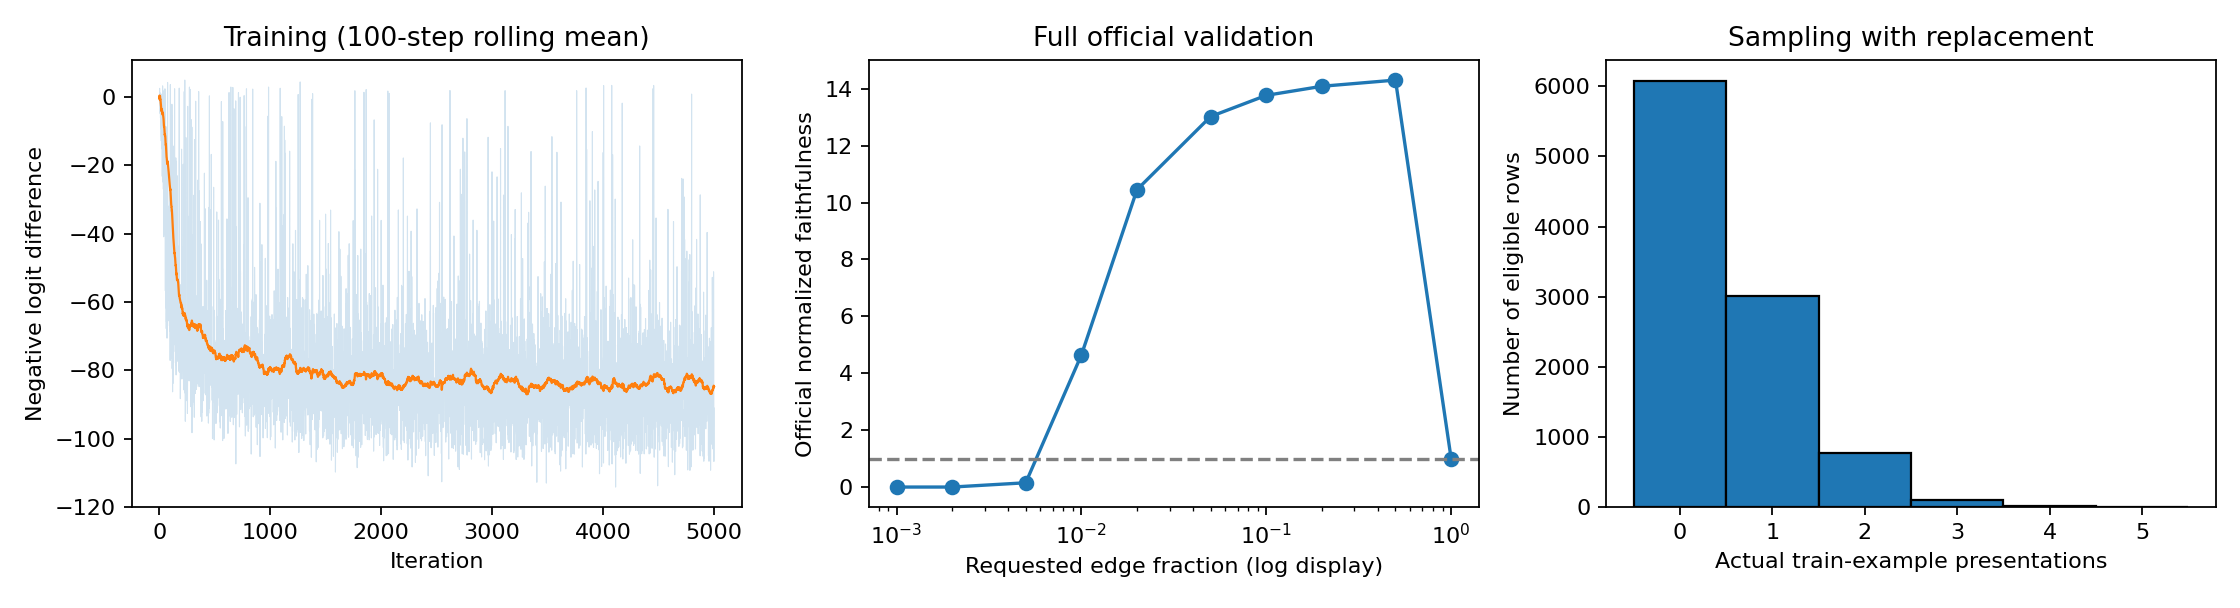

In [3]:
if RESULTS is not None:
    display(pd.Series(json.loads((RESULTS/'official_metrics.json').read_text())))
    display(pd.read_csv(RESULTS/'faithfulness_curve.csv'))
    accounting=RESULTS/'complete_compute_accounting.csv'
    display(pd.read_csv(accounting if accounting.exists() else RESULTS/'compute_accounting.csv'))
    gate=1 if (RESULTS/'gate1_passed.json').exists() else 0
    display(Image(filename=str(RESULTS/f'gate{gate}_diagnostics.png')))


## Execution gates

1. **Gate 0:** source inspection, metric/resume tests, short CUDA edge smoke.
2. **Gate 1:** one official 5,000-step edge baseline; explicit independent dispatch.
3. **Gate 2:** unchanged MAttr on nested 16/32/64/128 pools, fixed validation.
4. **Gate 3:** sampling ablations only after baseline noise and data scaling.
5. **Gate 4:** initialization with full EAP-IG cost; then optional Gate 5 refinement.
6. **Gate 6:** multi-model validation and submissions require explicit approval.

No hypothesis about algorithm improvements has been tested by the smoke run.


In [4]:
if RESULTS is not None:
    display(Markdown((RESULTS/'MATTR_BASELINE_REPORT.md').read_text()))
else:
    print('No completed Gate-0 experiment. Follow src/mattr_optimization/README.md.')


# MAttr optimization: Gate 1 official edge baseline

Campaign: `20261021T134352Z_gate1`. **Gate 1 completed.** Only the official baseline was run; Gate 2 and all algorithm modifications remain unrun.

## Protocol and provenance

Pinned MAttr `af82b2eef145dd3e66c793a413352d6931a152d7`, required MIB fork `582fdbc8a2b0f7063a265c8f94851fd2a3aa5480`; exact EAP commit, source/lock hashes, installed versions, command argv and execution-source snapshots are saved. A dedicated WSL Python 3.12 environment uses the official frozen dependency lock on RTX 3060 12 GB. Older environments and experiments were not changed.

GPT-2 Small, official MIB IOI, edge granularity (32,491 real scores), seed 42, 5,000 requested iterations; 5000 logged updates. The uncapped official train pool has 10000 rows and the uncapped validation split has 10000 rows, both in original official order. Clean prompts are distinct across splits and answer names were checked to be single tokens. No test split or custom IOI dataset was accessed.

Uniform floating k; sigmoid top-k; iso/denoising; zero score initialization; Adam lr 0.05, epsilon 1e-8, betas (0.9,0.999); T=.5; 30 bisection iterations. One example is sampled with replacement per training iteration. Evaluation batch=20, donor-cache budget=4.0 GB; explicit resource overrides relative to upstream defaults: {'evaluation_batch_size': False, 'counterfactual_cache_gb': False}. Float32/TF32 disabled. Upstream model-weight gradient accumulation is preserved; no freezing or algorithm optimization was introduced.

The adapter calls the upstream edge CLI, trainer, live-sender intervention closure and official signed edge evaluator. It adds counters, checkpointing and audited raw-vector exports. Versioned checkpoints restore scores, Adam and Python/NumPy/Torch/CUDA RNGs. Cached evaluation vectors are reused only after exact ranking, source/configuration, data fingerprint and vector-hash checks; reuses incur zero model forwards. Setup/replayed work is included in the complete accounting. No settings change automatically after OOM.

## Official validation results

- **CPR AUC: 10.58801242**.
- **CMD AUC: 9.60080915** (lower absolute deviation from full-model behavior).
- Accuracy log-AUC: 0.73720560.
- Clean mean logit difference: 3.24274755; official empty-circuit corrupted reference: -2.72592449.
- Maximum discrepancy in four post-training hard-mask checks against official MIB: 1.9073486e-06, within atol=5e-5/rtol=1e-5.

| Requested fraction | Requested edges | Faithfulness | Accuracy |
|---:|---:|---:|---:|
| 0.001 | 32 | 0.000000 | 0.0481 |
| 0.002 | 64 | -0.000011 | 0.0481 |
| 0.005 | 162 | 0.150415 | 0.1198 |
| 0.01 | 324 | 4.640131 | 0.9970 |
| 0.02 | 649 | 10.454853 | 1.0000 |
| 0.05 | 1624 | 13.024123 | 1.0000 |
| 0.1 | 3249 | 13.768633 | 1.0000 |
| 0.2 | 6498 | 14.088088 | 1.0000 |
| 0.5 | 16245 | 14.305707 | 1.0000 |
| 1 | 32491 | 1.000000 | 0.9740 |

Requested counts are before official connectivity pruning; weighted edge counts are saved separately. CPR uses the official linear retained-fraction trapezoids, with no added zero endpoint and no clipping. Accuracy log-AUC is a different metric. Values above one reflect overshoot; a larger CPR alone does not establish improved mechanistic fidelity. Raw per-example clean, corrupted and ten grid-point validation vectors, the learned ranking and score tensors are saved. Independent integration of the saved curve agrees with official CPR/CMD within 1e-6.

The post-run verifier exports `official_nested_ranking.csv` with the actual official Torch tie ordering, and `official_circuit_membership_summary.csv` with pruned circuit sizes and identity hashes at each grid point. `ranking.csv` is a score-sorted presentation table; use the official ranking/graph procedure when ties matter. This export changes no trained scores or benchmark results and executes no model forwards.

## Published comparison and research conclusion

The [paper v1, Table 4](https://arxiv.org/html/2609.25518v1) reports GPT-2/IOI edge validation CPR **10.59** for its 5,000-step recipe. Our result differs from that rounded target by **-0.001988**. Rounded-value agreement, if present, cannot establish precision beyond the published rounding; otherwise this is a reproduction gap to investigate before claiming an improvement. Hardware/library behavior, precise evaluation protocol, revision and numerical precision must be considered. Our earlier node-level CPR 1.83 and Gate-0 small-cohort CPR are not matched edge-baseline comparisons.

This one seed establishes the measured reference and feasibility, not improvement over MAttr, statistical significance, or leaderboard performance. Sampling, initialization and ranking refinement have not been tested. No success threshold has been selected from variant results.

## Compute and memory

- Training, including checkpoint work: 1616.4 seconds (26.94 min).
- Full official validation evaluation, including raw-vector export: 2536.3 seconds (42.27 min).
- Instrumented model/data/correctness/training/evaluation stages: 4180.3 seconds (69.67 min); interpreter startup/source verification/reporting are outside these stage totals.
- Measured process work after source/config preparation: 4217.3 seconds (70.29 min), including upstream graph construction, pretokenization, exports and time between instrumented stages. Source checks, interpreter startup and report generation are additional overhead.
- Resume data-preflight CPU work outside that process timer: 0.0 seconds; zero model forwards. The WSL wrapper verifies saved row contents/order before any restart.
- Maximum allocated CUDA memory across stages: 6.799 GiB; maximum reserved: 12.393 GiB.
- Maximum sampled CPU RSS across stages: 2.905 GiB.
- Real root forward batches: 21788; individual example-forwards: 249788; backward calls: 5000; optimizer updates this and archived attempts: 5000.
- Eligible train rows: 10000; actual unique sampled rows across attempts: 3925; actual presentations including repeated work: 5000.

CUDA synchronizes at stage boundaries. Counters observe actual root forwards, not counterfactual-cache hits; activation-checkpoint recomputation inside backward is not a new root forward and remains part of measured backward/training cost. Training has required score-gradient graphs; held-out evaluation and hard-mask correctness checks use no-grad. No full-model weight updates occur. Allocation peaks measure PyTorch allocator usage, not all system GPU memory.

The raw upstream console uses calendar/time.time timestamps; WSL clock jumps were observed during this run, including a negative printed pretokenization duration. Those calendar-based durations and progress rates are not used for compute conclusions. The accounting and process timers above use monotonic perf_counter with CUDA synchronization.

## Next gate

Stop here. Gate 2 should run unchanged edge MAttr on nested 16/32/64/128 discovery pools with one fixed validation cohort, seed 42 first, then 43/44 after feasibility. Use these runs to characterize baseline noise and freeze improvement criteria before testing algorithm variants. No automatic sweep, multi-model evaluation or leaderboard submission is scheduled.
